In [1]:
%pip install pymongo
%pip install --upgrade pymongo certifi
import pandas as pd
from pymongo import MongoClient
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import matplotlib.gridspec as gridspec
warnings.filterwarnings('ignore', category=FutureWarning)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:

# 1. Khởi tạo kết nối đến MongoDB Atlas
# Lưu ý: Khi nộp bài hoặc đẩy lên GitHub/Kaggle, bạn nhớ ẩn mật khẩu này đi nhé (dùng biến môi trường hoặc thư viện dotenv)
client = MongoClient('mongodb+srv://<username>:<password>@cluster0.mongodb.net/')
db = client['ecom_data_lab']

# 2. Truy vấn dữ liệu từ collections (Bỏ qua cột _id nội bộ của MongoDB)
cursor_shops = db['dim_shops'].find({}, {'_id': 0})
cursor_products = db['fact_products'].find({}, {'_id': 0})

# 3. Load toàn bộ dữ liệu vào Pandas DataFrame
df_shops = pd.DataFrame(list(cursor_shops))
df_products = pd.DataFrame(list(cursor_products))


## **Mục tiêu 1: Phân tích phân bố số lượng bán ra theo 4 phân khúc giá gốc để xác định phân khúc chủ lực.**

In [3]:
# ==============================================================================
# MỤC TIÊU 1: XỬ LÝ DỮ LIỆU - TÍNH PHÂN KHÚC GIÁ VÀ MERGE 2 BẢNG
# ==============================================================================
# Thiết lập style chung cho các biểu đồ đẹp hơn
plt.rcParams['font.family'] = 'sans-serif'
sns.set_theme(style="whitegrid")

# Tạo một bản sao từ dữ liệu MongoDB để không làm ảnh hưởng data gốc
df_obj1 = df_products.copy()

# 1. Xử lý cột Giảm giá
df_obj1['Giảm giá'] = df_obj1['Giảm giá'].fillna(0)
df_obj1['Giảm giá'] = df_obj1['Giảm giá'].apply(lambda x: 0.99 if pd.to_numeric(x, errors='coerce') >= 1 else pd.to_numeric(x, errors='coerce'))

# 2. Tính Giá gốc = Giá / (1 - Giảm giá)
df_obj1['Giá'] = pd.to_numeric(df_obj1['Giá'], errors='coerce')
df_obj1['Giá gốc'] = df_obj1['Giá'] / (1 - df_obj1['Giảm giá'])

# 3. Phân nhóm (Binning) thành 4 phân khúc
bins = [0, 100, 300, 500, np.inf]
labels = ['Dưới 100k', '100k - 300k', '300k - 500k', 'Trên 500k']
df_obj1['Phân khúc giá'] = pd.cut(df_obj1['Giá gốc'], bins=bins, labels=labels, right=False)

# 4. Merge df_obj1 với df_shops để lấy Loại cửa hàng
df_obj1 = df_obj1.merge(df_shops[['Seller ID', 'Loại cửa hàng']], 
                         left_on='Seller ID', 
                         right_on='Seller ID', 
                         how='left')

# 5. Gom nhóm tính tổng Đã bán (không phân loại shop lúc này)
df_summary_total = df_obj1.groupby('Phân khúc giá', observed=False)['Đã bán'].sum().reset_index()
total_sales = df_summary_total['Đã bán'].sum()
df_summary_total['Tỷ trọng (%)'] = (df_summary_total['Đã bán'] / total_sales) * 100

# 6. Gom nhóm theo Loại cửa hàng và Phân khúc giá (cho biểu đồ so sánh Shop Thường vs LazMall)
df_shop_type = df_obj1.groupby(['Loại cửa hàng', 'Phân khúc giá'], observed=False)['Đã bán'].sum().reset_index()
df_thuong = df_shop_type[df_shop_type['Loại cửa hàng'] == 'Shop Thường'].copy()
df_mall = df_shop_type[df_shop_type['Loại cửa hàng'] == 'LazMall'].copy()

print("✓ Dữ liệu đã được xử lý và merge hoàn tất")

✓ Dữ liệu đã được xử lý và merge hoàn tất


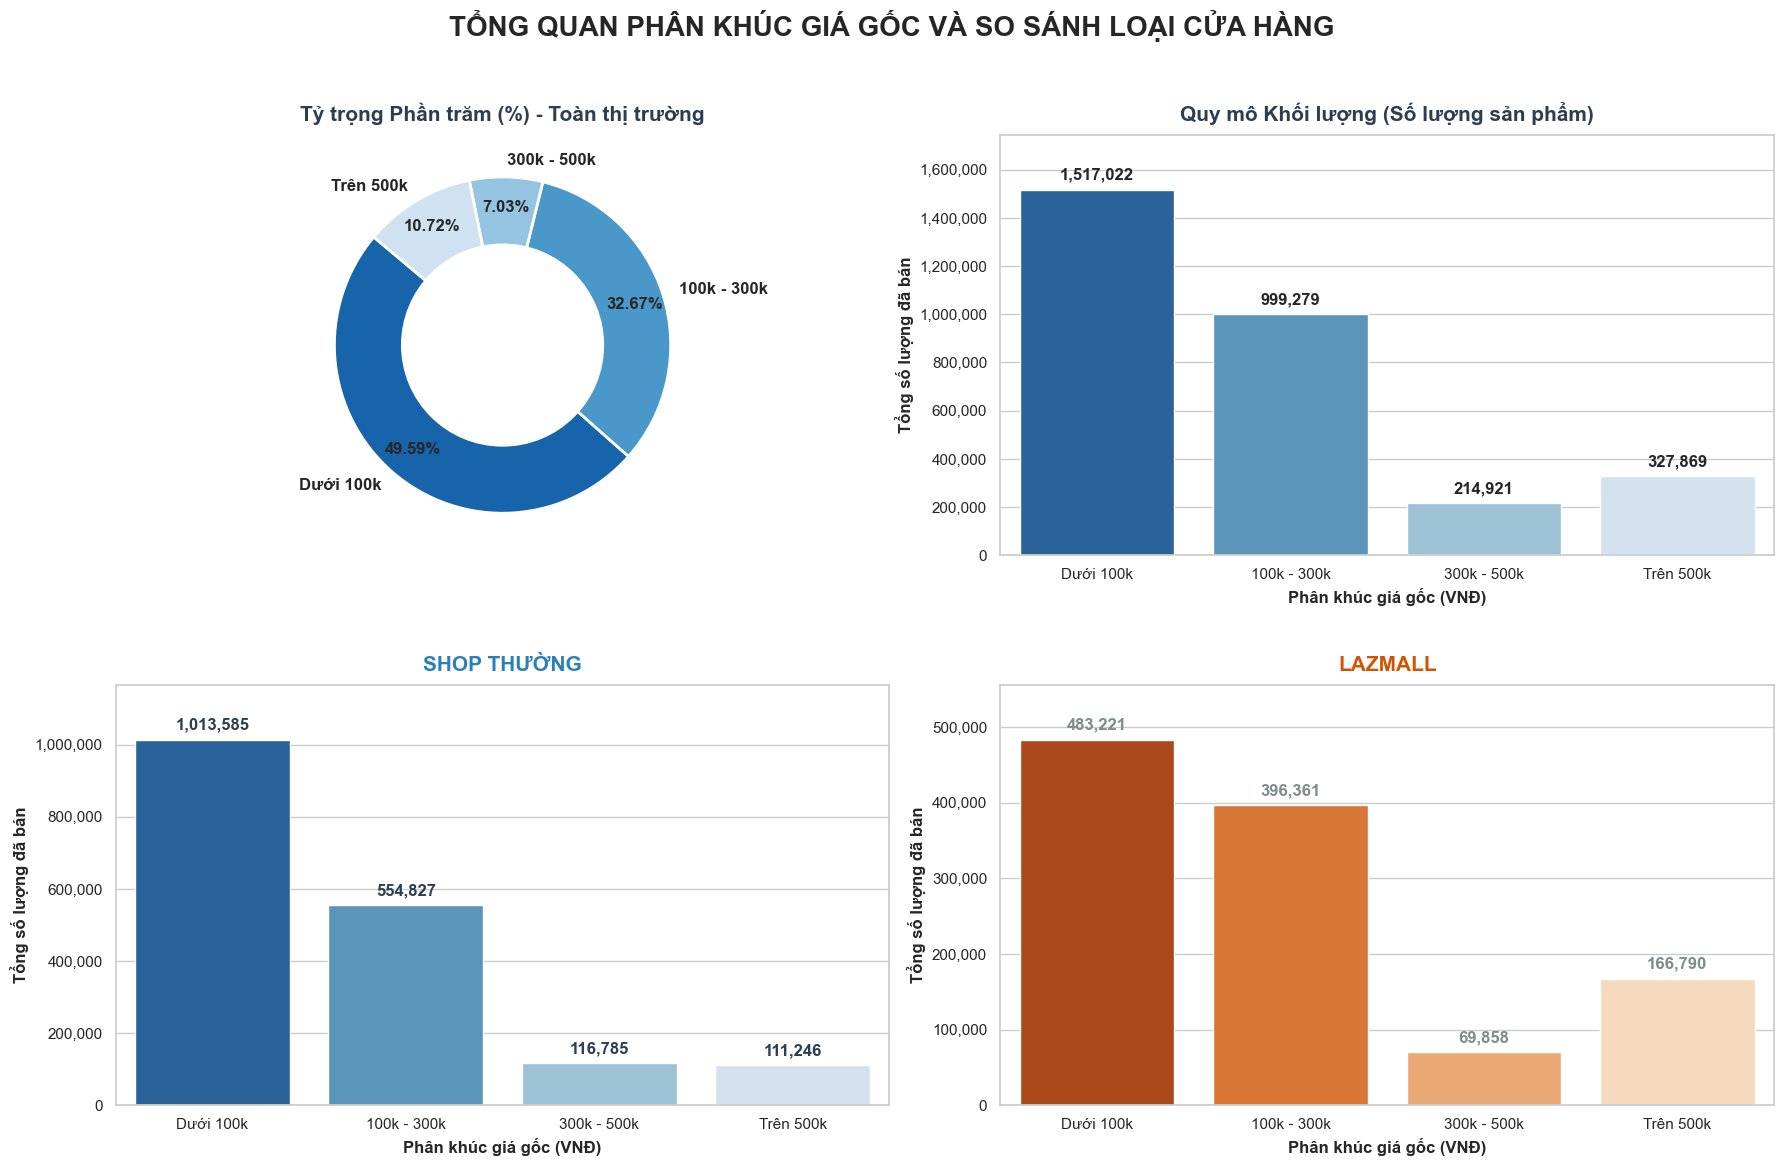

In [4]:
# ==============================================================================
# MỤC TIÊU 1: DASHBOARD TỔNG HỢP PHÂN KHÚC GIÁ & LOẠI CỬA HÀNG (2x2)
# ==============================================================================
# Ghi chú: Đảm bảo df_summary_total, df_thuong, df_mall đã được tính toán.

# Tạo Figure với 2 hàng và 2 cột, kích thước lớn để chứa đủ 4 biểu đồ
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Tiêu đề siêu to khổng lồ cho toàn bộ Dashboard
fig.suptitle('TỔNG QUAN PHÂN KHÚC GIÁ GỐC VÀ SO SÁNH LOẠI CỬA HÀNG', 
             fontsize=20, fontweight='bold', y=0.97)

# Lấy bảng màu xanh lam cho biểu đồ tổng thể
colors = sns.color_palette('Blues_r', len(df_summary_total))

# ---------------------------------------------------------
# 1. GÓC TRÊN TRÁI (axes[0, 0]): DONUT CHART - Tỷ trọng %
# ---------------------------------------------------------
axes[0, 0].pie(df_summary_total['Tỷ trọng (%)'], labels=df_summary_total['Phân khúc giá'], 
               autopct='%1.2f%%', startangle=140, colors=colors, pctdistance=0.82,
               textprops={'fontsize': 12, 'fontweight': 'bold'},
               wedgeprops={'edgecolor': 'white', 'linewidth': 2})

# Vẽ vòng tròn trắng ở giữa
centre_circle = plt.Circle((0,0), 0.60, fc='white')
axes[0, 0].add_artist(centre_circle)
axes[0, 0].set_title('Tỷ trọng Phần trăm (%) - Toàn thị trường', fontsize=15, fontweight='bold', color='#2c3e50', pad=10)

# ---------------------------------------------------------
# 2. GÓC TRÊN PHẢI (axes[0, 1]): BAR CHART - Tổng lượng bán
# ---------------------------------------------------------
sns.barplot(data=df_summary_total, x='Phân khúc giá', y='Đã bán', 
            hue='Phân khúc giá', palette='Blues_r', legend=False, ax=axes[0, 1])

axes[0, 1].set_title('Quy mô Khối lượng (Số lượng sản phẩm)', fontsize=15, fontweight='bold', color='#2c3e50', pad=10)
axes[0, 1].set_xlabel('Phân khúc giá gốc (VNĐ)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Tổng số lượng đã bán', fontsize=12, fontweight='bold')
axes[0, 1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Nới rộng trục Y thêm 15% để có chỗ viết số không bị đứt
max_total = df_summary_total['Đã bán'].max()
axes[0, 1].set_ylim(0, max_total * 1.15)

for i, v in enumerate(df_summary_total['Đã bán']):
    axes[0, 1].text(i, v + (max_total * 0.02), f'{v:,.0f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

# ---------------------------------------------------------
# 3. GÓC DƯỚI TRÁI (axes[1, 0]): SHOP THƯỜNG
# ---------------------------------------------------------
sns.barplot(data=df_thuong, x='Phân khúc giá', y='Đã bán', 
            hue='Phân khúc giá', palette='Blues_r', legend=False, ax=axes[1, 0])

axes[1, 0].set_title('SHOP THƯỜNG', fontsize=15, fontweight='bold', color='#2980b9', pad=10)
axes[1, 0].set_xlabel('Phân khúc giá gốc (VNĐ)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Tổng số lượng đã bán', fontsize=12, fontweight='bold')
axes[1, 0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

max_thuong = df_thuong['Đã bán'].max()
axes[1, 0].set_ylim(0, max_thuong * 1.15)

for i, v in enumerate(df_thuong['Đã bán']):
    axes[1, 0].text(i, v + (max_thuong * 0.02), f'{v:,.0f}', ha='center', va='bottom', fontsize=12, fontweight='bold', color='#2c3e50')

# ---------------------------------------------------------
# 4. GÓC DƯỚI PHẢI (axes[1, 1]): LAZMALL
# ---------------------------------------------------------
sns.barplot(data=df_mall, x='Phân khúc giá', y='Đã bán', 
            hue='Phân khúc giá', palette='Oranges_r', legend=False, ax=axes[1, 1])

axes[1, 1].set_title('LAZMALL', fontsize=15, fontweight='bold', color='#d35400', pad=10)
axes[1, 1].set_xlabel('Phân khúc giá gốc (VNĐ)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Tổng số lượng đã bán', fontsize=12, fontweight='bold')
axes[1, 1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

max_mall = df_mall['Đã bán'].max()
axes[1, 1].set_ylim(0, max_mall * 1.15)

for i, v in enumerate(df_mall['Đã bán']):
    axes[1, 1].text(i, v + (max_mall * 0.02), f'{v:,.0f}', ha='center', va='bottom', fontsize=12, fontweight='bold', color='#7f8c8d')

# ---------------------------------------------------------
# Căn chỉnh và xuất hình
# ---------------------------------------------------------
# Dùng rect để chừa khoảng an toàn ở trên, và h_pad=3.0 để tạo lề dọc giữa 2 hàng
plt.tight_layout(rect=[0, 0, 1, 0.95], h_pad=3.0)
plt.show()

## **Mục tiêu 2: Đánh giá tác động của mức giảm giá sâu (>30%) đối với nhóm sản phẩm thuộc phân khúc giá cao (trên 500k)**


C:\Users\luong\AppData\Local\Temp\ipykernel_30160\3277832205.py:117: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


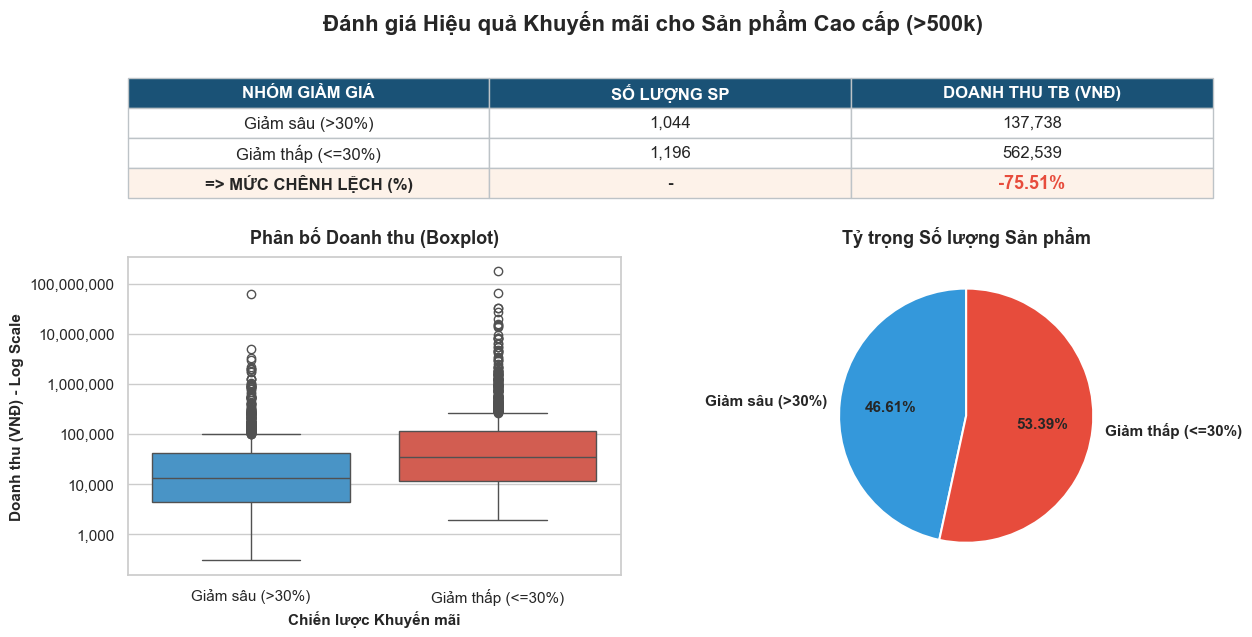

In [7]:
# ==============================================================================
# CELL HOÀN CHỈNH MỤC TIÊU 2: DASHBOARD (ÉP NGẮN CHIỀU CAO BOXPLOT)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec

# Thiết lập style chung
plt.rcParams['font.family'] = 'sans-serif'
sns.set_theme(style="whitegrid")

# 1. Chuẩn bị dữ liệu
df_obj2 = df_products.copy()
df_obj2['Giảm giá'] = df_obj2['Giảm giá'].fillna(0).apply(lambda x: 0.99 if pd.to_numeric(x, errors='coerce') >= 1 else pd.to_numeric(x, errors='coerce'))
df_obj2['Giá'] = pd.to_numeric(df_obj2['Giá'], errors='coerce')
df_obj2['Đã bán'] = pd.to_numeric(df_obj2['Đã bán'], errors='coerce').fillna(0)

# Tính Giá gốc và Doanh thu
df_obj2['Giá gốc'] = df_obj2['Giá'] / (1 - df_obj2['Giảm giá'])
df_obj2['Doanh thu'] = df_obj2['Giá'] * df_obj2['Đã bán']

# 2. Lọc dữ liệu: CHỈ LẤY SẢN PHẨM CÓ GIÁ GỐC > 500k
df_high_price = df_obj2[df_obj2['Giá gốc'] > 500].copy()

# 3. Phân loại theo 2 nhóm Giảm giá sâu (>30%) và Giảm thấp (<=30%)
df_high_price['Nhóm giảm giá'] = np.where(df_high_price['Giảm giá'] > 0.3, 'Giảm sâu (>30%)', 'Giảm thấp (<=30%)')

# 4. Gom nhóm để tính Tổng số SP và Doanh thu trung bình
summary_obj2 = df_high_price.groupby('Nhóm giảm giá', observed=False).agg(
    Số_lượng_SP=('ID Sản phẩm', 'count'),
    Doanh_thu_TB=('Doanh thu', 'mean')
).reset_index()

# 5. Lấy số liệu cụ thể để tính toán chênh lệch
sl_giam_sau = summary_obj2.loc[summary_obj2['Nhóm giảm giá'] == 'Giảm sâu (>30%)', 'Số_lượng_SP'].values[0]
dt_giam_sau = summary_obj2.loc[summary_obj2['Nhóm giảm giá'] == 'Giảm sâu (>30%)', 'Doanh_thu_TB'].values[0]

sl_giam_thap = summary_obj2.loc[summary_obj2['Nhóm giảm giá'] == 'Giảm thấp (<=30%)', 'Số_lượng_SP'].values[0]
dt_giam_thap = summary_obj2.loc[summary_obj2['Nhóm giảm giá'] == 'Giảm thấp (<=30%)', 'Doanh_thu_TB'].values[0]

chenh_lech_pct = ((dt_giam_sau - dt_giam_thap) / dt_giam_thap) * 100

# ==============================================================================
# BẮT ĐẦU VẼ DASHBOARD TỔNG HỢP (SUPER COMPACT)
# ==============================================================================
# Khởi tạo khung hình thu hẹp chiều cao (14x6.5) để Boxplot lùn lại
fig = plt.figure(figsize=(14, 6.5))
fig.suptitle('Đánh giá Hiệu quả Khuyến mãi cho Sản phẩm Cao cấp (>500k)', 
             fontsize=16, fontweight='bold', y=0.98)

# Chỉnh tỷ lệ để ép hàng dưới lùn xuống thêm một chút so với bảng
gs = gridspec.GridSpec(2, 2, height_ratios=[0.8, 2], hspace=0.25)

# Tạo các vùng vẽ (Axes)
ax_table = fig.add_subplot(gs[0, :])
ax_box = fig.add_subplot(gs[1, 0])
ax_pie = fig.add_subplot(gs[1, 1])

# ---------------------------------------------------------
# PHẦN 1 (TRÊN CÙNG): VẼ BIỂU ĐỒ BẢNG (TABLE)
# ---------------------------------------------------------
ax_table.axis('off')
table_data = [
    ['Giảm sâu (>30%)', f"{sl_giam_sau:,.0f}", f"{dt_giam_sau:,.0f}"],
    ['Giảm thấp (<=30%)', f"{sl_giam_thap:,.0f}", f"{dt_giam_thap:,.0f}"],
    ['=> MỨC CHÊNH LỆCH (%)', '-', f"{chenh_lech_pct:,.2f}%"]
]
columns = ['NHÓM GIẢM GIÁ', 'SỐ LƯỢNG SP', 'DOANH THU TB (VNĐ)']

table = ax_table.table(cellText=table_data, colLabels=columns, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1, 1.8) 

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#bdc3c7')
    if row == 0:
        cell.set_facecolor('#1A5276')
        cell.set_text_props(color='white', weight='bold')
    elif row == 3:
        cell.set_facecolor('#fdf2e9')
        cell.set_text_props(weight='bold')
        if col == 2: 
            text_color = '#e74c3c' if chenh_lech_pct < 0 else '#2ecc71'
            cell.set_text_props(color=text_color, weight='bold', fontsize=13)
    else:
        cell.set_facecolor('#ffffff')

# ---------------------------------------------------------
# PHẦN 2 (DƯỚI TRÁI): BOXPLOT - PHÂN BỐ DOANH THU
# ---------------------------------------------------------
order_list = ['Giảm sâu (>30%)', 'Giảm thấp (<=30%)']
sns.boxplot(data=df_high_price, x='Nhóm giảm giá', y='Doanh thu', 
            palette=['#3498db', '#e74c3c'], order=order_list, ax=ax_box)

ax_box.set_title('Phân bố Doanh thu (Boxplot)', fontsize=13, fontweight='bold', pad=10)
ax_box.set_xlabel('Chiến lược Khuyến mãi', fontsize=11, fontweight='bold')
ax_box.set_yscale('log')
ax_box.set_ylabel('Doanh thu (VNĐ) - Log Scale', fontsize=11, fontweight='bold')
ax_box.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,.0f}".format(int(x))))

# ---------------------------------------------------------
# PHẦN 3 (DƯỚI PHẢI): PIE CHART - TỶ TRỌNG SỐ LƯỢNG
# ---------------------------------------------------------
sizes = [sl_giam_sau, sl_giam_thap]
labels = ['Giảm sâu (>30%)', 'Giảm thấp (<=30%)']

ax_pie.pie(sizes, labels=labels, autopct='%1.2f%%', startangle=90, 
           colors=['#3498db', '#e74c3c'],
           textprops={'fontsize': 11, 'fontweight': 'bold'},
           wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})

ax_pie.set_title('Tỷ trọng Số lượng Sản phẩm', fontsize=13, fontweight='bold', pad=10)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## **Mục tiêu 3: Phân nhóm các mức giảm giá thành 5 khoảng để xác định "khoảng giảm giá tối ưu"**

In [8]:
# Thiết lập style chung
plt.rcParams['font.family'] = 'sans-serif'
sns.set_theme(style="whitegrid")

# 1. Chuẩn bị dữ liệu
df_obj3 = df_products.copy()

# Xử lý các cột số liệu
df_obj3['Giảm giá'] = df_obj3['Giảm giá'].fillna(0).apply(lambda x: 0.99 if pd.to_numeric(x, errors='coerce') >= 1 else pd.to_numeric(x, errors='coerce'))
df_obj3['Giá'] = pd.to_numeric(df_obj3['Giá'], errors='coerce')
df_obj3['Đã bán'] = pd.to_numeric(df_obj3['Đã bán'], errors='coerce').fillna(0)

# Tính Doanh thu ước tính (Giá hiện tại * Đã bán)
df_obj3['Doanh thu'] = df_obj3['Giá'] * df_obj3['Đã bán']

# 2. Chia Bin (Gom nhóm) các mức Giảm giá thành 5 khoảng
# Dùng bins=[-0.01, ...] để bao hàm cả những sản phẩm giảm giá 0%
bins = [-0.01, 0.10, 0.20, 0.30, 0.50, np.inf]
labels = ['0 - 10%', '10% - 20%', '20% - 30%', '30% - 50%', '> 50%']

df_obj3['Khoảng giảm giá'] = pd.cut(df_obj3['Giảm giá'], bins=bins, labels=labels)

# 3. Gom nhóm tính Số lượng sản phẩm và Doanh thu trung bình
summary_obj3 = df_obj3.groupby('Khoảng giảm giá', observed=False).agg(
    Số_lượng_SP=('ID Sản phẩm', 'count'),
    Doanh_thu_TB=('Doanh thu', 'mean')
).reset_index()

# Tìm ra Khoảng giảm giá tối ưu (Sweet spot)
sweet_spot = summary_obj3.loc[summary_obj3['Doanh_thu_TB'].idxmax()]

print("="*60)
print(f"🎯 KẾT QUẢ TÌM KIẾM 'SWEET SPOT' (KHOẢNG TỐI ƯU):")
print(f"- Khoảng giảm giá mang lại doanh thu TB cao nhất: {sweet_spot['Khoảng giảm giá']}")
print(f"- Doanh thu TB đạt: {sweet_spot['Doanh_thu_TB']:,.0f} VNĐ")
print("="*60)

# 4. In bảng định dạng Xanh Corporate (Gọn gàng)
def style_summary_obj3(df):
    styles = [
        {'selector': 'th', 'props': [('background-color', '#1A5276'), ('color', '#FFFFFF'), ('font-weight', 'bold'), ('text-transform', 'uppercase'), ('text-align', 'center'), ('padding', '12px 20px'), ('border-bottom', '3px solid #0E2B3D')]},
        {'selector': 'td', 'props': [('background-color', '#FFFFFF'), ('color', '#2C3E50'), ('text-align', 'center'), ('padding', '10px 20px'), ('border-bottom', '1px solid #EAEDED')]},
        {'selector': 'tr:hover td', 'props': [('background-color', '#EBF5FB'), ('color', '#1A5276'), ('font-weight', 'bold')]}
    ]
    return df.style.set_table_styles(styles).format({'Số_lượng_SP': '{:,.0f}', 'Doanh_thu_TB': '{:,.0f}'}).hide(axis='index')

print("\nBẢNG THỐNG KÊ DOANH THU THEO 5 KHOẢNG GIẢM GIÁ:")
display(style_summary_obj3(summary_obj3))

🎯 KẾT QUẢ TÌM KIẾM 'SWEET SPOT' (KHOẢNG TỐI ƯU):
- Khoảng giảm giá mang lại doanh thu TB cao nhất: 0 - 10%
- Doanh thu TB đạt: 263,974 VNĐ

BẢNG THỐNG KÊ DOANH THU THEO 5 KHOẢNG GIẢM GIÁ:


Khoảng giảm giá,Số_lượng_SP,Doanh_thu_TB
0 - 10%,"2,296","263,974"
10% - 20%,631,"146,417"
20% - 30%,"1,042","101,281"
30% - 50%,"2,086","88,920"
> 50%,966,"56,328"


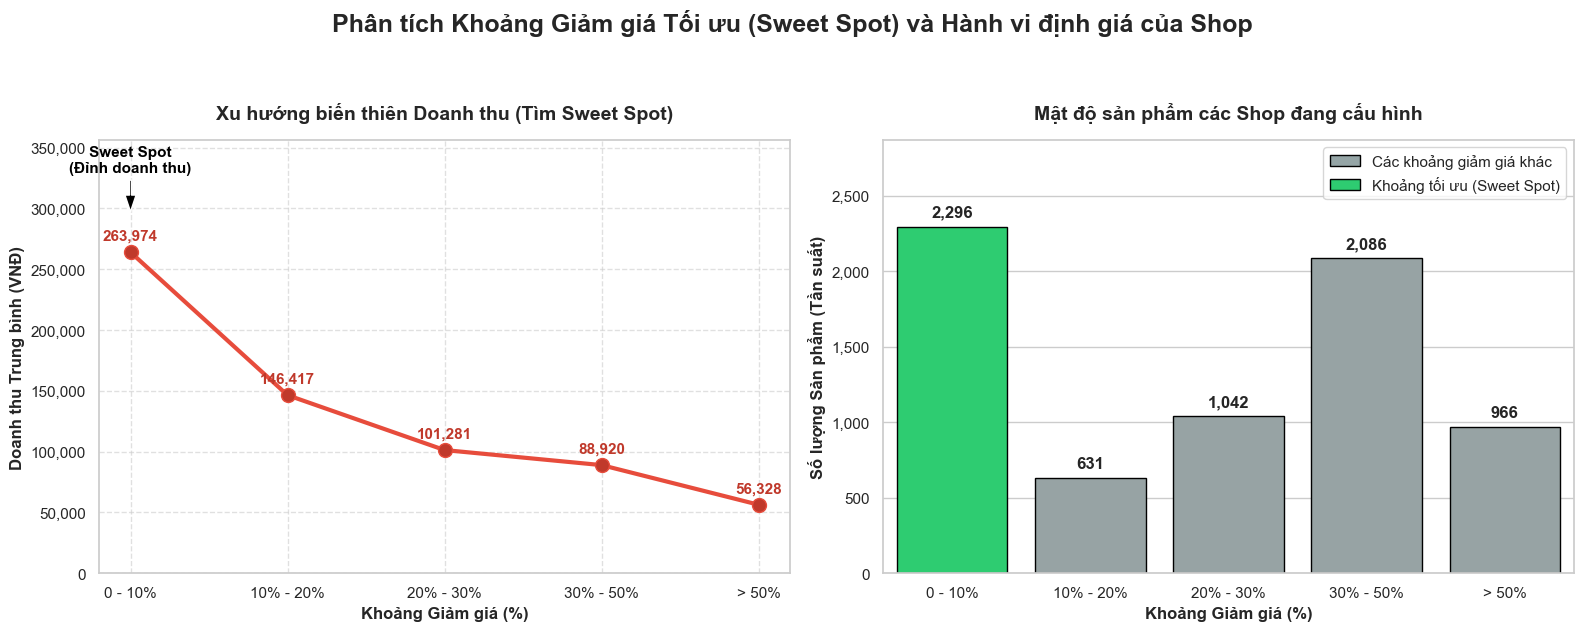

In [9]:
# ==============================================================================
# CELL 2 (MỚI TỐI ƯU): COMBO LINE CHART & HISTOGRAM - CHỈNH SỬA TRÙNG LẶP (OVERLAP)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Phân tích Khoảng Giảm giá Tối ưu (Sweet Spot) và Hành vi định giá của Shop', 
             fontsize=18, fontweight='bold', y=1.05)

# ---------------------------------------------------------
# ĐỒ THỊ 1 (BÊN TRÁI): LINE CHART KÈM MARKER (Đường cong doanh thu)
# ---------------------------------------------------------
axes[0].plot(summary_obj3['Khoảng giảm giá'], summary_obj3['Doanh_thu_TB'], 
             color='#e74c3c', marker='o', linewidth=3, markersize=10, markerfacecolor='#c0392b')

axes[0].set_title('Xu hướng biến thiên Doanh thu (Tìm Sweet Spot)', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Khoảng Giảm giá (%)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Doanh thu Trung bình (VNĐ)', fontsize=12, fontweight='bold')
axes[0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[0].grid(True, linestyle='--', alpha=0.6)

# NỚI RỘNG TRỤC Y BÊN TRÁI THÊM 35% ĐỂ CÓ CHỖ VIẾT CHỮ
max_doanhthu = summary_obj3['Doanh_thu_TB'].max()
axes[0].set_ylim(0, max_doanhthu * 1.35)

# Gắn số liệu lên từng chấm tròn (đẩy lên trên một chút so với điểm)
for i, v in enumerate(summary_obj3['Doanh_thu_TB']):
    axes[0].text(i, v + (max_doanhthu * 0.03), f'{v:,.0f}', ha='center', va='bottom', fontsize=11, fontweight='bold', color='#c0392b')

# Đánh dấu "Sweet Spot" (Mũi tên chỉ lửng lơ trên con số, không chạm vào số)
max_idx = summary_obj3['Doanh_thu_TB'].idxmax()
axes[0].annotate('Sweet Spot\n(Đỉnh doanh thu)', 
                 xy=(max_idx, max_doanhthu * 1.12), # Đầu mũi tên nằm trên con số
                 xytext=(max_idx, max_doanhthu * 1.25), # Chữ nằm tuốt trên cao
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
                 ha='center', fontsize=11, fontweight='bold', color='black')

# ---------------------------------------------------------
# ĐỒ THỊ 2 (BÊN PHẢI): HISTOGRAM (Phân bố số lượng sản phẩm)
# ---------------------------------------------------------
sns.barplot(data=summary_obj3, x='Khoảng giảm giá', y='Số_lượng_SP', color='#95a5a6', edgecolor='black', ax=axes[1])

# Đổi màu riêng cho cột chứa "Sweet Spot"
axes[1].patches[max_idx].set_facecolor('#2ecc71')

axes[1].set_title('Mật độ sản phẩm các Shop đang cấu hình', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Khoảng Giảm giá (%)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Số lượng Sản phẩm (Tần suất)', fontsize=12, fontweight='bold')
axes[1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# NỚI RỘNG TRỤC Y BÊN PHẢI THÊM 25% ĐỂ CÓ CHỖ ĐẶT LEGEND (CHÚ THÍCH)
max_sp = summary_obj3['Số_lượng_SP'].max()
axes[1].set_ylim(0, max_sp * 1.25)

# Gắn nhãn số lượng trên các cột
for i, v in enumerate(summary_obj3['Số_lượng_SP']):
    axes[1].text(i, v + (max_sp * 0.02), f'{v:,.0f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

# Thêm chú thích giải thích màu (Sẽ nằm an toàn ở khoảng trống phía trên)
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#95a5a6', edgecolor='black', label='Các khoảng giảm giá khác'),
    Patch(facecolor='#2ecc71', edgecolor='black', label='Khoảng tối ưu (Sweet Spot)')
]
axes[1].legend(handles=legend_elements, fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

## **Mục tiêu 4: Tính toán hệ số tương quan (Correlation) giữa tỷ lệ giảm giá (%) và lượng bán ra.**

- Hệ số tương quan (r) giữa Giảm giá và Đã bán: 0.0136


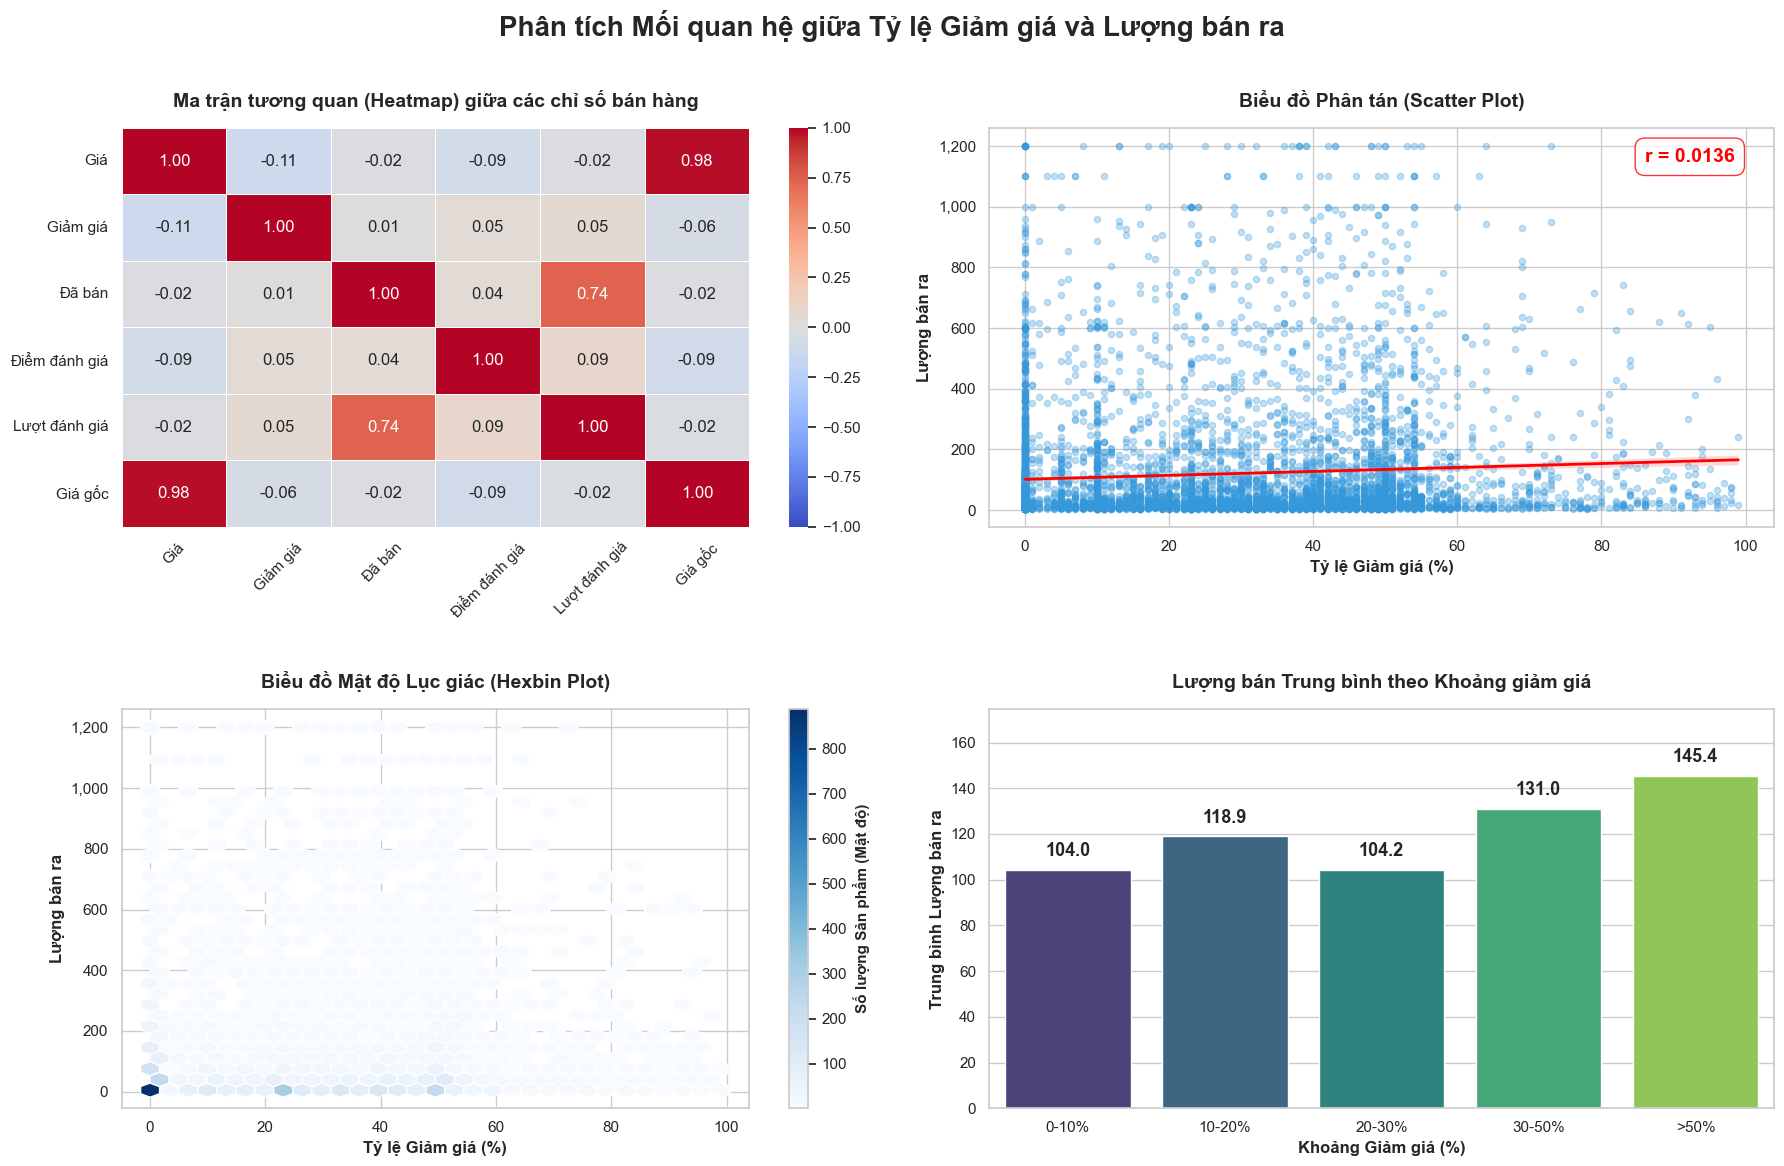

In [10]:
# ==============================================================================
# CELL HOÀN CHỈNH MỤC TIÊU 4: DASHBOARD 2x2 (GIỮ NGUYÊN 100% CODE CỦA BẠN)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập style chung
plt.rcParams['font.family'] = 'sans-serif'
sns.set_theme(style="whitegrid")

# ---------------------------------------------------------
# 1. CHUẨN BỊ VÀ LÀM SẠCH DỮ LIỆU (Code gốc của bạn)
# ---------------------------------------------------------
df_obj4 = df_products.copy()

# Chuyển đổi kiểu dữ liệu và xử lý lỗi
df_obj4['Giảm giá'] = df_obj4['Giảm giá'].fillna(0).apply(lambda x: 0.99 if pd.to_numeric(x, errors='coerce') >= 1 else pd.to_numeric(x, errors='coerce'))
df_obj4['Đã bán'] = pd.to_numeric(df_obj4['Đã bán'], errors='coerce').fillna(0)
df_obj4['Giá'] = pd.to_numeric(df_obj4['Giá'], errors='coerce')
df_obj4['Điểm đánh giá'] = pd.to_numeric(df_obj4['Điểm đánh giá'], errors='coerce').fillna(0)
df_obj4['Lượt đánh giá'] = pd.to_numeric(df_obj4['Lượt đánh giá'], errors='coerce').fillna(0)

# Tính Giá gốc
df_obj4['Giá gốc'] = df_obj4['Giá'] / (1 - df_obj4['Giảm giá'])

# Lấy TẤT CẢ các cột dạng số (numeric)
numeric_cols = df_obj4.select_dtypes(include=[np.number]).columns.tolist()

# Bỏ qua các ID (nếu có)
cols_to_remove = ['ID Sản phẩm', 'Seller ID']
for col in cols_to_remove:
    if col in numeric_cols:
        numeric_cols.remove(col)

# Tính ma trận tương quan (Pearson) trên df_obj4
corr_matrix = df_obj4[numeric_cols].corr()

# Lấy hệ số r giữa Giảm giá và Đã bán để kết luận
r_value = corr_matrix.loc['Giảm giá', 'Đã bán'] if 'Giảm giá' in corr_matrix.columns else 0

# In kết quả kiểm chứng
print("="*60)
print(f"- Hệ số tương quan (r) giữa Giảm giá và Đã bán: {r_value:.4f}")

# ---------------------------------------------------------
# 2. XỬ LÝ DỮ LIỆU CHO SCATTER & HEXBIN (Code gốc của bạn)
# ---------------------------------------------------------
df_corr = df_obj4.copy()

# Tạo cột Lượng bán ra và Giảm giá (%)
df_corr['Lượng bán ra'] = df_corr['Đã bán']
df_corr['Giảm giá (%)'] = df_corr['Giảm giá'] * 100

# Lọc Outliers cho Scatter và Hexbin
q95_sales = df_corr['Lượng bán ra'].quantile(0.95)
df_zoom = df_corr[df_corr['Lượng bán ra'] <= q95_sales].copy()

# ---------------------------------------------------------
# 3. VẼ DASHBOARD TỔNG HỢP 4 BIỂU ĐỒ (2x2)
# ---------------------------------------------------------
# Tạo Figure với 2 hàng, 2 cột
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Phân tích Mối quan hệ giữa Tỷ lệ Giảm giá và Lượng bán ra', 
             fontsize=20, fontweight='bold', y=0.97)

# --- [GÓC TRÊN TRÁI] ĐỒ THỊ 1: HEATMAP ---
sns.heatmap(corr_matrix, 
            annot=True,          
            fmt=".2f",           
            cmap='coolwarm',     
            linewidths=0.5,      
            vmin=-1, vmax=1, ax=axes[0, 0])    

axes[0, 0].set_title('Ma trận tương quan (Heatmap) giữa các chỉ số bán hàng', fontsize=14, fontweight='bold', pad=15)
axes[0, 0].tick_params(axis='x', rotation=45, labelsize=11)
axes[0, 0].tick_params(axis='y', rotation=0, labelsize=11)

# --- [GÓC TRÊN PHẢI] ĐỒ THỊ 2: SCATTER PLOT ---
sns.regplot(data=df_zoom, x='Giảm giá (%)', y='Lượng bán ra', ax=axes[0, 1],
            scatter_kws={'alpha': 0.3, 'color': '#3498db', 's': 20},
            line_kws={'color': 'red', 'linewidth': 2})

axes[0, 1].set_title('Biểu đồ Phân tán (Scatter Plot)', fontsize=14, fontweight='bold', pad=15)
axes[0, 1].set_xlabel('Tỷ lệ Giảm giá (%)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Lượng bán ra', fontsize=12, fontweight='bold')
axes[0, 1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Ghi chú hệ số r (lấy từ Heatmap theo đúng code của bạn)
axes[0, 1].text(0.95, 0.95, f'r = {r_value:.4f}', transform=axes[0, 1].transAxes, 
             fontsize=14, fontweight='bold', color='red', ha='right', va='top',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='red', alpha=0.8))

# --- [GÓC DƯỚI TRÁI] ĐỒ THỊ 3: HEXBIN PLOT ---
hb = axes[1, 0].hexbin(df_zoom['Giảm giá (%)'], df_zoom['Lượng bán ra'], 
                    gridsize=30, cmap='Blues', edgecolors='white', mincnt=1)

axes[1, 0].set_title('Biểu đồ Mật độ Lục giác (Hexbin Plot)', fontsize=14, fontweight='bold', pad=15)
axes[1, 0].set_xlabel('Tỷ lệ Giảm giá (%)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Lượng bán ra', fontsize=12, fontweight='bold')
axes[1, 0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Thêm thanh màu (Colorbar) cho Hexbin
cb = fig.colorbar(hb, ax=axes[1, 0])
cb.set_label('Số lượng Sản phẩm (Mật độ)', fontsize=11, fontweight='bold')

# --- [GÓC DƯỚI PHẢI] ĐỒ THỊ 4: BAR CHART ---
bins = [-1, 10, 20, 30, 50, 100]
labels = ['0-10%', '10-20%', '20-30%', '30-50%', '>50%']
df_zoom['Khoảng giảm giá'] = pd.cut(df_zoom['Giảm giá (%)'], bins=bins, labels=labels)
avg_sales = df_zoom.groupby('Khoảng giảm giá', observed=False)['Lượng bán ra'].mean().reset_index()

sns.barplot(data=avg_sales, x='Khoảng giảm giá', y='Lượng bán ra', 
            hue='Khoảng giảm giá', palette='viridis', legend=False, ax=axes[1, 1])

axes[1, 1].set_title('Lượng bán Trung bình theo Khoảng giảm giá', fontsize=14, fontweight='bold', pad=15)
axes[1, 1].set_xlabel('Khoảng Giảm giá (%)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Trung bình Lượng bán ra', fontsize=12, fontweight='bold')
axes[1, 1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

max_avg = avg_sales['Lượng bán ra'].max()
axes[1, 1].set_ylim(0, max_avg * 1.2) # Nới trần trục Y

for i, v in enumerate(avg_sales['Lượng bán ra']):
    axes[1, 1].text(i, v + (max_avg * 0.03), f'{v:,.1f}', ha='center', va='bottom', fontsize=13, fontweight='bold')

# --- CĂN CHỈNH VÀ XUẤT HÌNH ---
plt.tight_layout(rect=[0, 0, 1, 0.96], h_pad=3.0, w_pad=2.0)
plt.show()